# Rollout error vs. training trajectories and model width

This notebook explores `results/sweep.csv`: one row per trained model (training trajectories × MLP width × seed).

- **Rollout error** is the RMS position difference between a simulation driven by the learned forces and one driven by the true forces, from the same held-out start, at time t = 1 (200 steps). It's averaged over 16 starts.
- All plots use **log-log axes**, so a straight line means a power law, `error ∝ x^slope`.

**Setup** (from the repo root):

```bash
pip install -e ".[notebook]"
jupyter notebook notebooks/explore_results.ipynb
```

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image

import rollscale as rs
from rollscale.plotting import aggregate

rows = rs.read_results(Path("..") / "results" / "sweep.csv")
print(len(rows), "trained models")
print("trajectories:", sorted({r["n_traj"] for r in rows}))
print("widths:      ", sorted({r["width"] for r in rows}))
print("seeds:       ", sorted({r["seed"] for r in rows}))

126 trained models
trajectories: [1, 2, 4, 8, 16, 32, 64]
widths:       [4, 8, 16, 32, 64, 128]
seeds:        [0, 1, 2]


## 1. The two scaling views

Lines are medians over seeds; shaded bands span the min and max across seeds.

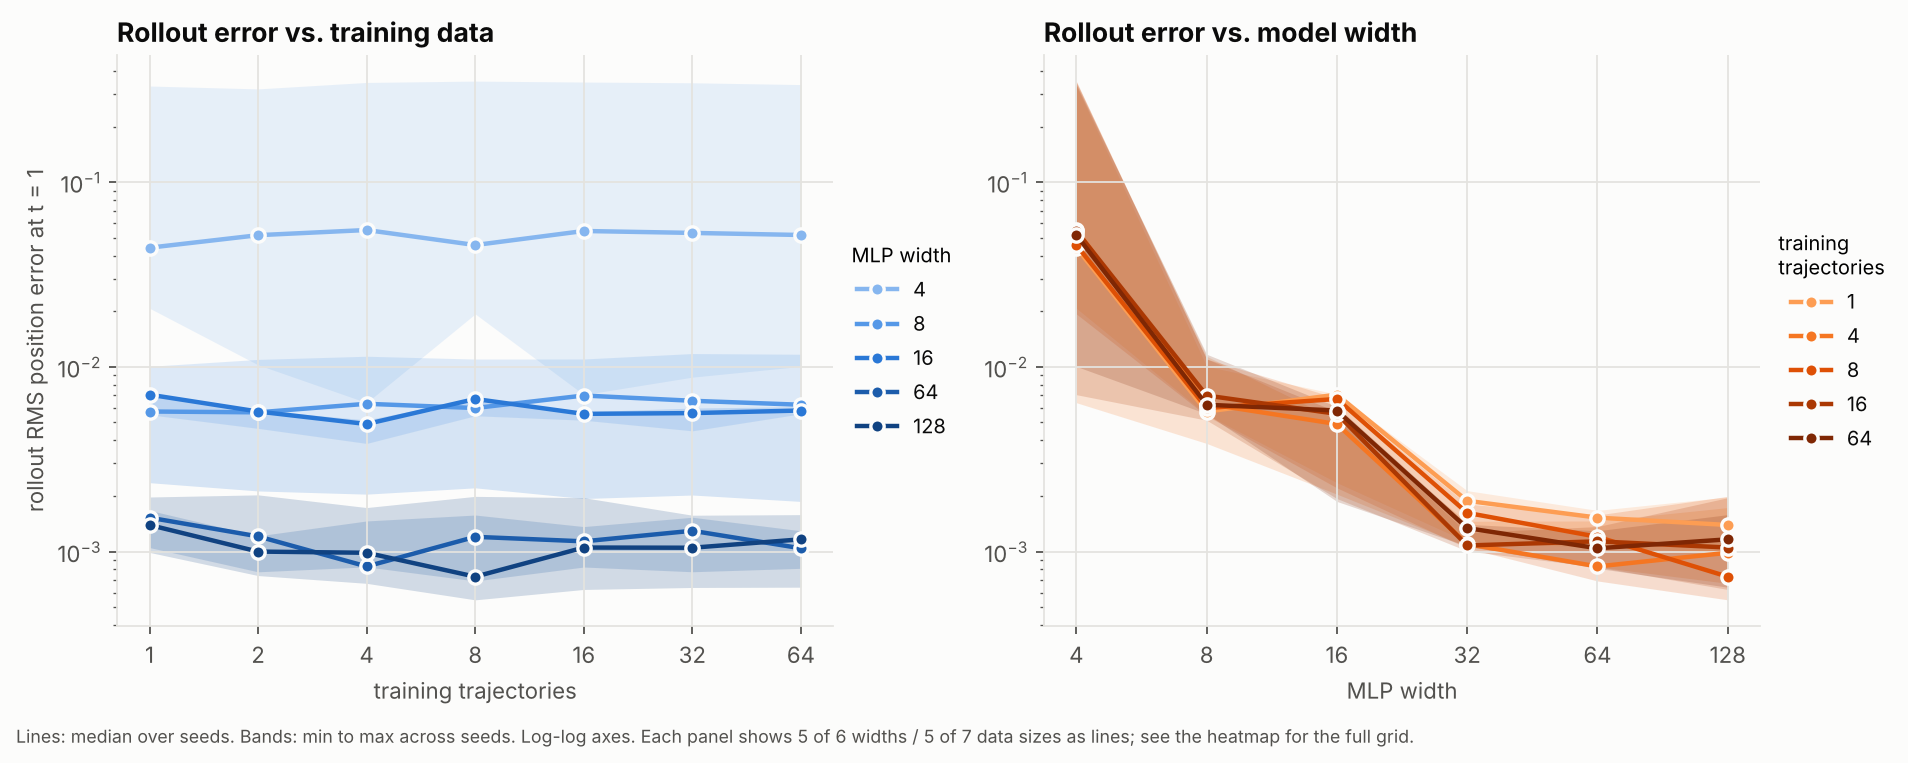

In [2]:
Image(filename=rs.plot_scaling(rows, "scaling.png"))

## 2. The full grid

Every (trajectories, width) combination, median over seeds.

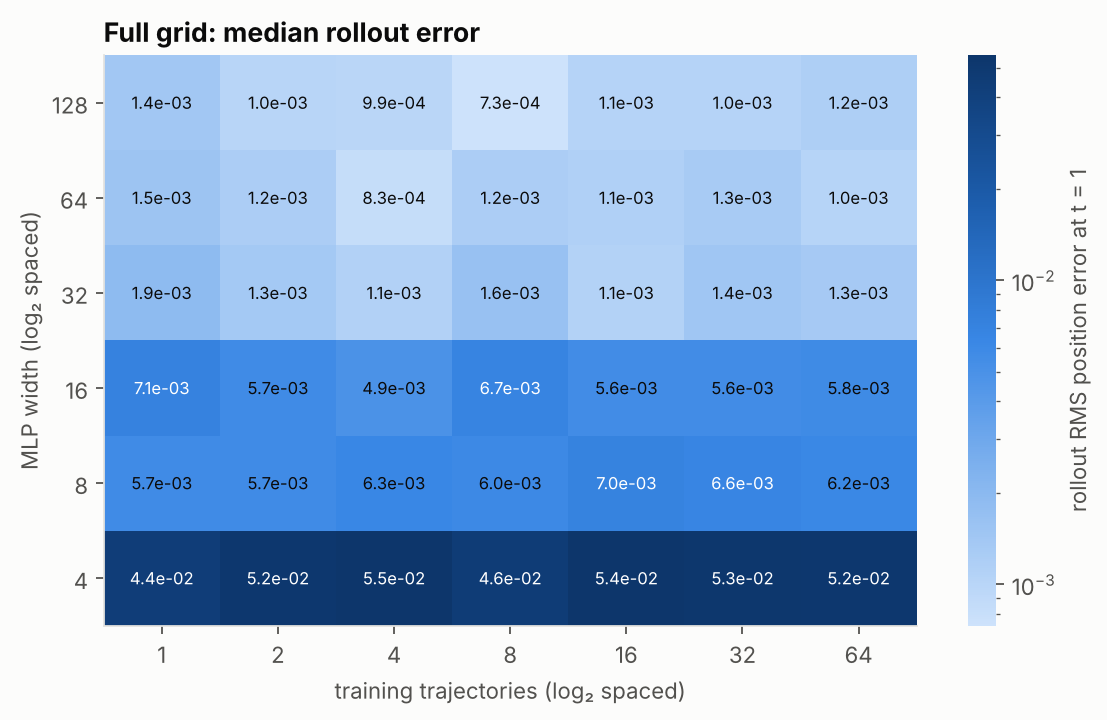

In [3]:
Image(filename=rs.plot_heatmap(rows, "heatmap.png"))

## 3. Power-law slopes

Slope of log(median error) against log(trajectories) or log(width). A slope of −1 means doubling the quantity halves the error.

In [4]:
metric = "rollout_t1"
print("vs. training trajectories (one row per width)")
for w, (xs, med, _lo, _hi) in aggregate(rows, "n_traj", "width", metric).items():
    print(f"  width {w:4d}: slope {rs.power_law_slope(xs, med):+.2f}   error {med[0]:.1e} -> {med[-1]:.1e}")
print("\nvs. width (one row per number of trajectories)")
for n, (xs, med, _lo, _hi) in aggregate(rows, "width", "n_traj", metric).items():
    print(f"  {n:3d} traj: slope {rs.power_law_slope(xs, med):+.2f}   error {med[0]:.1e} -> {med[-1]:.1e}")

vs. training trajectories (one row per width)
  width    4: slope +0.03   error 4.4e-02 -> 5.2e-02
  width    8: slope +0.03   error 5.7e-03 -> 6.2e-03
  width   16: slope -0.03   error 7.1e-03 -> 5.8e-03
  width   32: slope -0.05   error 1.9e-03 -> 1.3e-03
  width   64: slope -0.04   error 1.5e-03 -> 1.0e-03
  width  128: slope -0.02   error 1.4e-03 -> 1.2e-03

vs. width (one row per number of trajectories)
    1 traj: slope -0.93   error 4.4e-02 -> 1.4e-03
    2 traj: slope -1.06   error 5.2e-02 -> 1.0e-03
    4 traj: slope -1.14   error 5.5e-02 -> 9.9e-04
    8 traj: slope -1.11   error 4.6e-02 -> 7.3e-04
   16 traj: slope -1.11   error 5.4e-02 -> 1.1e-03
   32 traj: slope -1.07   error 5.3e-02 -> 1.0e-03
   64 traj: slope -1.06   error 5.2e-02 -> 1.2e-03


## 4. Why rollout error tracks force error

Before chaos saturates it, the rollout error should be roughly proportional to how wrong the forces are.

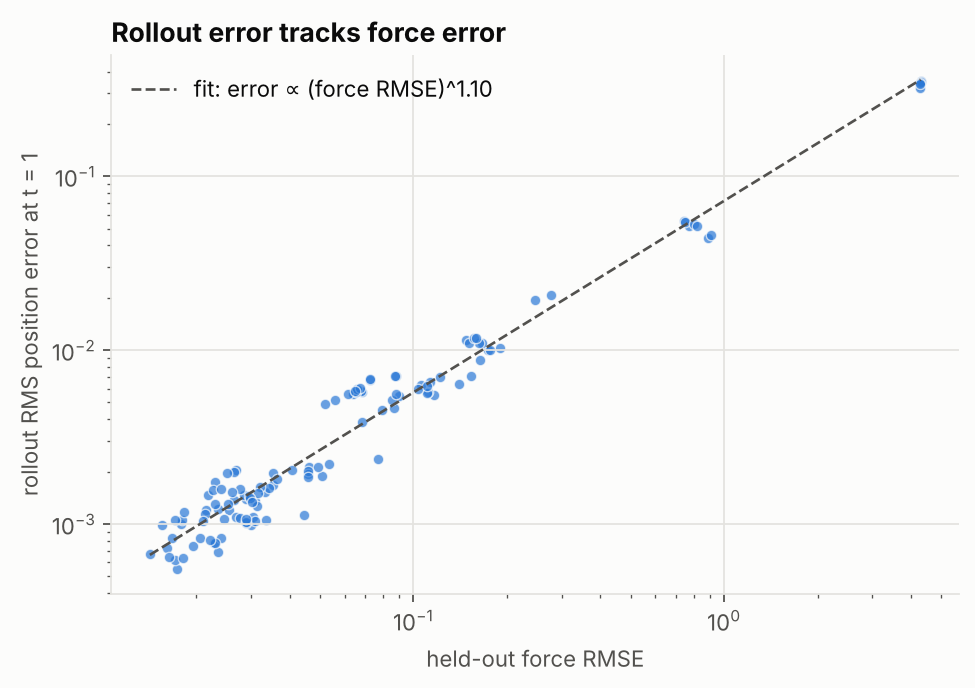

In [5]:
Image(filename=rs.plot_force_vs_rollout(rows, "force_vs_rollout.png"))

## 5. Other horizons

The same view at t = 0.5 and t = 2.5. At longer horizons, chaos amplifies every model's error and the curves bunch together near the saturation level (about 0.15–0.2).

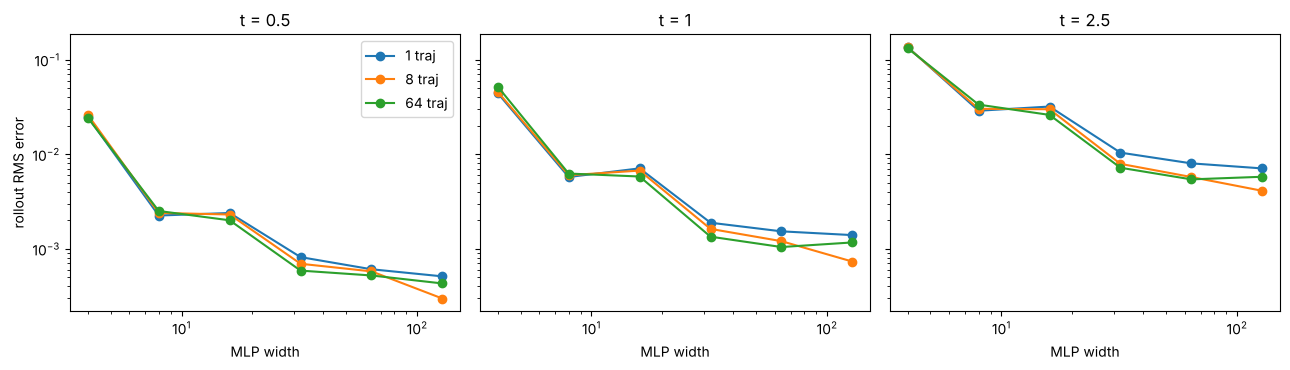

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, metric in zip(axes, ["rollout_t0.5", "rollout_t1", "rollout_t2.5"], strict=True):
    for n in [1, 8, 64]:
        xs, med, lo, hi = aggregate(rows, "width", "n_traj", metric)[n]
        ax.plot(xs, med, "o-", label=f"{n} traj")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("MLP width")
    ax.set_title(metric.replace("rollout_t", "t = "))
axes[0].set_ylabel("rollout RMS error")
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. Run a mini sweep yourself

The full grid takes about an hour on a CPU (`python scripts/run_sweep.py`). This cell runs a 4-model version in under a minute, writing to `notebooks/mini.csv`. Change the lists and re-run; finished runs are skipped.

In [7]:
cfg = rs.SweepConfig(n_trajs=(1, 16), widths=(8, 32), seeds=(0,), steps=800, n_test_starts=8)
mini = rs.run_sweep(cfg, "mini.csv")
for r in mini:
    print(f"n_traj={r['n_traj']:3d} width={r['width']:3d}  rollout(t=1)={r['rollout_t1']:.2e}")

0 runs already in mini.csv; 4 to go


[  1/4] n_traj=  1 width=   8 seed=0  rollout(t=1)=2.55e-02  force RMSE=4.46e-01  (4 s)


[  2/4] n_traj=  1 width=  32 seed=0  rollout(t=1)=9.54e-03  force RMSE=1.44e-01  (12 s)


[  3/4] n_traj= 16 width=   8 seed=0  rollout(t=1)=1.89e-02  force RMSE=3.10e-01  (3 s)


[  4/4] n_traj= 16 width=  32 seed=0  rollout(t=1)=8.94e-03  force RMSE=1.19e-01  (12 s)
n_traj=  1 width=  8  rollout(t=1)=2.55e-02
n_traj=  1 width= 32  rollout(t=1)=9.54e-03
n_traj= 16 width=  8  rollout(t=1)=1.89e-02
n_traj= 16 width= 32  rollout(t=1)=8.94e-03
